In [1]:
import yaml
import numpy as np
from matplotlib import pyplot as plt

# --- Custom Utility Module --
from flux_history import FluxHistory
from mineral_utils import Paleodetector

In [2]:
mineral_name =  "Olivine"

overburden_history = {
    "initial_depth": 0.2
}

time = 1. / (24 * 365.25 * 1e3)
h_obs_km = 11.

flux_history_flight  = FluxHistory(baseline={"kind": "Baseline", "h_obs_km": h_obs_km})

In [3]:
MINERAL_LIBRARY = yaml.safe_load(open('Data/mineral_library.yaml', 'r'))
mineral_config = MINERAL_LIBRARY.get(mineral_name)


mineral_flight = Paleodetector(mineral_config, total_age_kyr=time, flux_history=flux_history_flight, overburden_history=overburden_history)

Interpolating overburden history...
Time grid: 100 nodes over 0-1.14077e-07 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Olivine, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 58.17 GeV in 82 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; se

In [4]:
x_bins, tracks_flight = mineral_flight.integrate_all_particles()

Time grid: 100 nodes over 0-1.14077e-07 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)


 20%|██        | 1/5 [01:55<07:43, 115.95s/it]

 60%|██████    | 3/5 [02:21<01:19, 39.69s/it] 

100%|██████████| 5/5 [06:33<00:00, 78.74s/it]


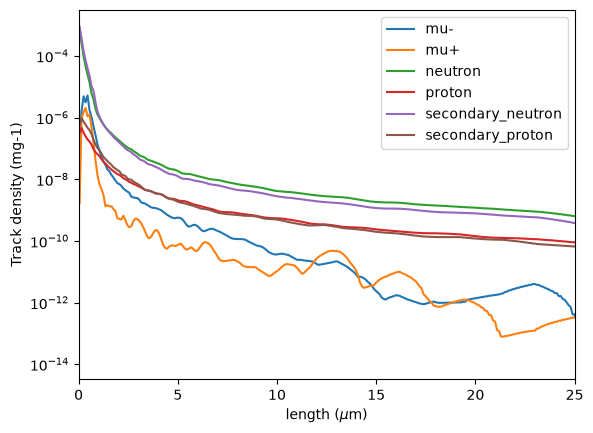

In [5]:
x_mids = x_bins[:-1] + np.diff(x_bins) / 2     

for species in mineral_flight.available_species():

    plt.plot(x_mids/1000., tracks_flight[species], label = species)
plt.xlim(0, 25.)
plt.ylabel("Track density (mg-1)")
plt.xlabel(rf"length ($\mu$m)")
plt.yscale('log')
plt.legend()

In [6]:
tracks_flight["x_bins"] = x_bins
np.savez(f"Data/tracks_{mineral_name}_1hr{h_obs_km}km_flight", tracks_flight)